### Fraud Detection
##### Objective: Build a machine learning pipeline to detect fraudulent financial transactions from a heavily imbalanced dataset, addressing class imbalance as a core challenge.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load the data
credit_fraud = pd.read_csv('creditcard.csv')

In [3]:
# Data info 
credit_fraud.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
credit_fraud.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
# Class imbalance
print(credit_fraud['Class'].value_counts())
print(credit_fraud['Class'].value_counts(normalize=True))

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


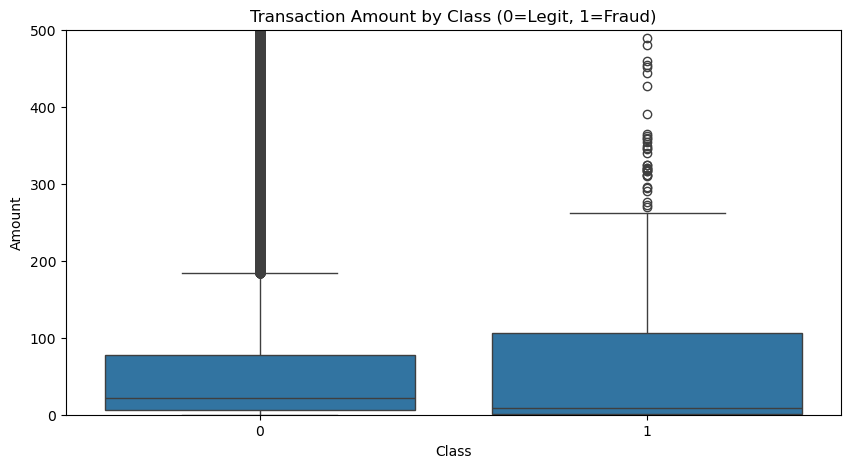

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


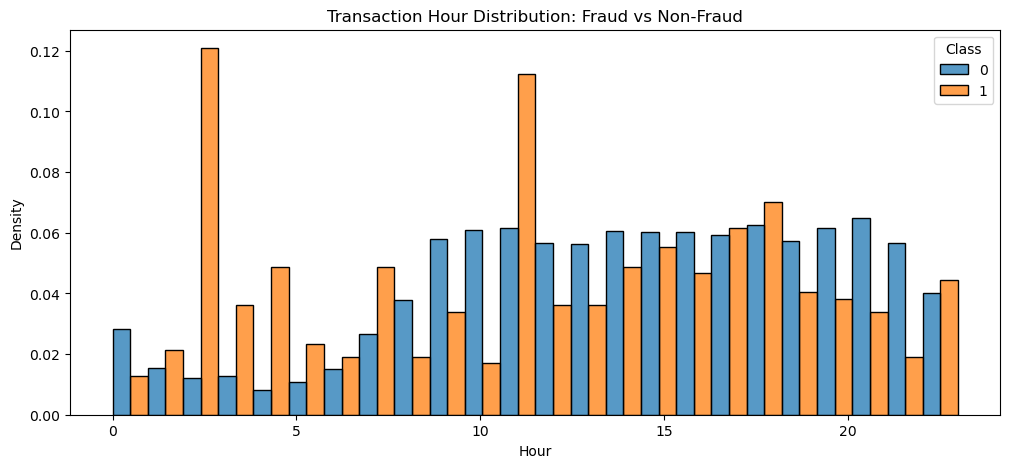

In [6]:
# Amount distribution: fraud vs non-fraud
plt.figure(figsize=(10, 5))
sns.boxplot(x='Class', y='Amount', data=credit_fraud)
plt.title('Transaction Amount by Class (0=Legit, 1=Fraud)')
plt.ylim(0, 500) 
plt.show()

# Compare summary stats directly
print(credit_fraud.groupby('Class')['Amount'].describe())

# Time-of-day analysis
# 'Time' is seconds since first transaction - convert to hour of day
credit_fraud['Hour'] = (credit_fraud['Time'] // 3600) % 24

plt.figure(figsize=(12, 5))
sns.histplot(data=credit_fraud, x='Hour', hue='Class', bins=24,
             stat='density', common_norm=False, multiple='dodge')
plt.title('Transaction Hour Distribution: Fraud vs Non-Fraud')
plt.show()

**Why Accuracy Is a Misleading Metric Here**

This dataset is extremely imbalanced: only 492 of 284,807 transactions (0.73%) are fraudulent. A model that predict "not fraud" for every single transaction would score 99.8% accuracy - while catching zero fraud cases. In a real fraud-detection system, that "high accuracy" model is worthless: it lets every fraudulent transaction through.

Because the positive class (fraud) is so rare, accuracy is dominated by how well the model handles the negative class (legit transactions), which is trivial. What actually matters is how well the model identifies the rare fraud cases - which is why we need Precision, Recall, F1-Score, and AUC-ROC instead, evaluated specifically on the minority class.

In [7]:
from sklearn.model_selection import train_test_split

X = credit_fraud.drop(['Class', 'Hour'], axis=1)
Y = credit_fraud['Class']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

print(Y_train.value_counts())
print(Y_test.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


In [8]:
# SMOTE (oversampling minority class)
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, Y_train_smote = smote.fit_resample(X_train, Y_train)

print("Before SMOTE:", Y_train.value_counts().to_dict())
print("After SMOTE:", Y_train_smote.value_counts().to_dict())

Before SMOTE: {0: 227451, 1: 394}
After SMOTE: {0: 227451, 1: 227451}


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_smote, Y_train_smote)

# Model 2: Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_smote, Y_train_smote)

print('Both models trained')

C:\Users\HP\anaconda_projects\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Both models trained


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Scale ALL feature columns
X_train_smote_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_smote),
    columns=X_train_smote.columns,
    index=X_train_smote.index
)
X_test_scaled = pd.DataFrame(
    scaler.fit_transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Re-train Logistic Regression on fully scaled data
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_smote_scaled, Y_train_smote)

print('Logistic Regression retrained - check for warning')

Logistic Regression retrained - check for warning


=== Logistic Regression ===
              precision    recall  f1-score   support

           0     1.0000    0.0403    0.0774     56864
           1     0.0018    1.0000    0.0036        98

    accuracy                         0.0419     56962
   macro avg     0.5009    0.5201    0.0405     56962
weighted avg     0.9983    0.0419    0.0773     56962

AUC-ROC: 0.9222183720843432

=== Random Forest ===
              precision    recall  f1-score   support

           0     0.9997    0.9997    0.9997     56864
           1     0.8438    0.8265    0.8351        98

    accuracy                         0.9994     56962
   macro avg     0.9217    0.9131    0.9174     56962
weighted avg     0.9994    0.9994    0.9994     56962

AUC-ROC: 0.9694113523997105


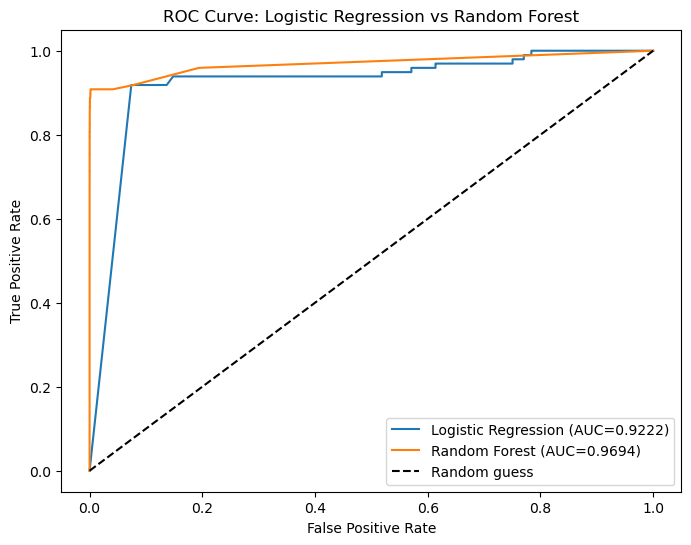

In [16]:
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

# --- Logistic Regression (uses SCALED test data) ---
Y_pred_log = log_reg.predict(X_test_scaled)
Y_proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]

print('=== Logistic Regression ===')
print(classification_report(Y_test, Y_pred_log, digits=4))
print('AUC-ROC:', roc_auc_score(Y_test, Y_proba_log))

# --- Random Forest (uses ORIGINAL unscaled test data) ---
Y_pred_rf = rf.predict(X_test)
Y_proba_rf = rf.predict_proba(X_test)[:, 1]

print('\n=== Random Forest ===')
print(classification_report(Y_test, Y_pred_rf, digits=4))
print('AUC-ROC:', roc_auc_score(Y_test, Y_proba_rf))

# --- AUC-ROC curve, both models on one plot ---
fpr_log, tpr_log, _ = roc_curve(Y_test, Y_proba_log)
fpr_rf, tpr_rf, _ = roc_curve(Y_test, Y_proba_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC={roc_auc_score(Y_test, Y_proba_log):.4f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC={roc_auc_score(Y_test, Y_proba_rf):.4f})')
plt.plot([0,1], [0,1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Logistic Regression vs Random Forest')
plt.legend()
plt.show()

**Model Comparison Notes**

Logistic Regression achieved a strong AUC-ROC (0.9222), showing it can rank fraud vs. non-fraud reasonably well overall. However, at the default 0.5 decision threshold, its precision for fraud collapsed to 0.0018 (recall 1.0000) - it flagged the overwhelming majority of test transactions as fraud. This happens because Logistic Regression was trained on SMOTE-balanced data (50/50 fraud/non-fraud), so it learned a decision boundary calibrated for a 50/50 world. Applied to the real, heavily imbalanced test set (0.17% fraud), that boundary is miscalibrated
and over-predicts fraud. This is a known limitation of resampling techniques: rebalancing the training data can shift where the optimal classification threshold sits, and the default 0.5 cutoff is no longer approriate.

Random Forest did not suffer from this issueto the same degree (precision 0.8438, recall 0.8265, F1 0.8351, AUC-ROC 0.9694) - likely because tree-based splits are less sensitive to the shifted class balanced than a linear probability threshold. For deployment, Random Forest's result are directly usable; Logistic Regression's threshold would need to be tuned (e.g., using the ROC or precision-recall curve) before it could be trusted in production.

**Which Metric Matters Most: Recall vs. Precision**

For fraud detection, **recall** is generally the more import metric. Missing a fraudulent transaction (a false negative) means a customer loses money and the fraud goes undetected - a direct financial loss. A false positive (flagging a legitimate transaction as fraud) is costly too - it inconveniences a real customer and burdens the review team - but it's a recoverable, lower-stakes error compared to letting fraud through undetected.

That said, precision cannot be ignored entirely. A model with very low precision (like our Logistic Regression example above) creates so many false alarms that it becomes operationally useless - customer support and fraud review teams would be overwhelmed, and legitimate customers would face constant false declines, damaging trust in business.

In practice, the goal is to **maximize recall subject to a precision constraint the business can operationally support** - for example, "catch as much fraud as possible while keeping fasle-positive rate low enough that fraud review team isn't overwhilmed."" Random Forest's balanced here (Recall 0.8265, Precision 0.8438) represents a much more production viable trade-off than Logistic Regression's collapsed precision.

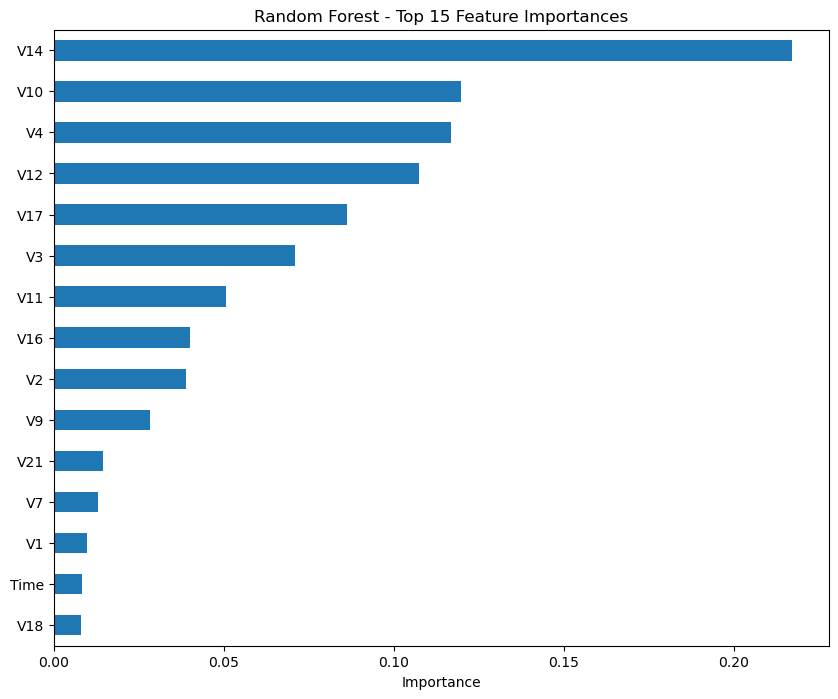

Top 10 Random Forest features:
V14    0.217013
V10    0.119797
V4     0.116789
V12    0.107501
V17    0.086248
dtype: float64


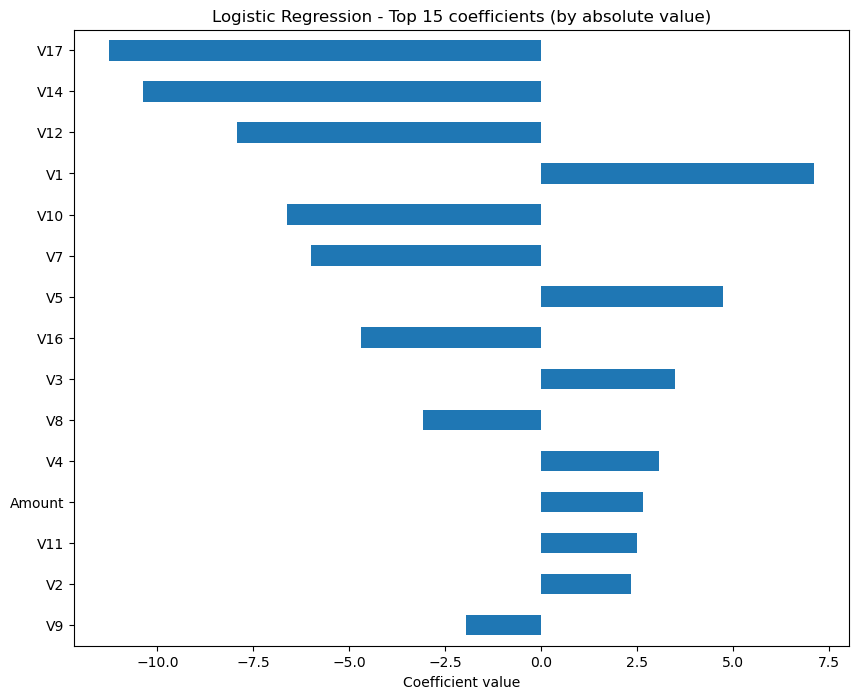


Top 10 Logistic Regression coefficients:
V17   -11.250611
V14   -10.382002
V12    -7.937263
V1      7.106124
V10    -6.632616
dtype: float64


In [18]:
import numpy as np

# --- Randm Forest feature importance ---
rf_importances = pd.Series(rf.feature_importances_, index=X_train.columns)
rf_importances = rf_importances.sort_values(ascending=False)

plt.figure(figsize=(10,8))
rf_importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Random Forest - Top 15 Feature Importances')
plt.xlabel('Importance')
plt.show()

print("Top 10 Random Forest features:")
print(rf_importances.head())

# --- Logistic Regression coefficients ---
log_reg_coefs = pd.Series(log_reg.coef_[0], index=X_train_smote_scaled.columns)
log_reg_coefs_sorted = log_reg_coefs.reindex(log_reg_coefs.abs().sort_values(ascending=False).index)

plt.figure(figsize=(10,8))
log_reg_coefs_sorted.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Logistic Regression - Top 15 coefficients (by absolute value)')
plt.xlabel('Coefficient value')
plt.show()

print("\nTop 10 Logistic Regression coefficients:")
print(log_reg_coefs_sorted.head())

**Feature Importance / Coefficient Analysis**

Both models independently identified overlapping top features - V14, V17, V10, and V12 rank highly in both Random Forest's importance scores and logistic regression's coefficient - despite the two algorithms working in fundamentally different ways (tree-based splits vs. linear weights). This agreement is a strong signal that these anonymized components genuinely separate fraud from legitimate transactions, rather than being a quirk of one particular model.

For Logistic Regression, negative coefficients (e.g., V17: -11.25, V14: -10.38, V12: -7.94, V10: -6.63) mean higher values of these features push the prediction *away* from fraud, while positive coefficients (e.g., V1: +7.11) push *toward* fraud.

Since V1-V28 are PCA-transformed components (per the dataset's anonymization for confidentiality), we cannot map these back to real-world meaning like "transaction location" or "merchant category." This limits interpretability for business stakeholders - we can say *which* components matter, but not *why* in plain business terms. In a non-anonymized production setting, engineering interpretable features would allow this kind of analysis to directly inform fraud prevention policy.

**Scalability: Handling 1 Million Transaction Per Hour**

1 million transactions/hour is roughly 278 transactions/second - a real-time production workload very different from this notebook's batch analysis of ~285k historical rows. Several changes would be needed to scale this pipeline:

**1. Inference speed over training convenience**
Random Forest with 100 trees is fast enough for real-time scoring (microseconds pre prediction), but at this volume even small per-presdiction costs add up. A lighter model (e.g., a smaller Random Forest, or a gradient-boosted model like XGBoost/LightGBM tuned for low-latency inference) would likely be evaluated against Random Forest's accuracy to find the right speend/accuracy trade-off.

**2. Streaming, not batch**
Instead of loading a full CSV into memory, transactions would arrive as a continuous stream (e.g., via Apache Kafka or a similar message queue). The model would score each transaction as it arrives, rather than processing a static dataset.

**3. Horizontal scaling**
A single machine cannot serve 278 predictions/second relaiably under load spikes. The model would be deployed behind a load balancer across multiple inference servers, so demand is distributed rather than bottlenecked on one machine.

**4. Feature computation at speed**
Real-time features (e.g., "transactions by this card in the last hour") require fast lookups, typically from an in-memory store (e.g., Redis) rather than recomputing from a full historical table on every request.

**5. Retraining and drift monitoring**
Fraud patterns evolve as fraudsters adapt. A production system needs scheduled retraining (e.g., weekly/monthly) on fresh data, plus monitoring for model drift - a drop in precision/recall over time would signal that fraud patterns have shifted and the model needs updating.

**6. Asynchronous handling of borderline cases**
Not every prediction needs to block the transaction in real time. High-confidence fraud can be decline instantly; borderline cases can be flagged for asynchronous human review without holding up the transaction, balancing customer experience with fraud prevention.

In short: this notebook's model logic (SMOTE handling, evaluation metrics, feature analysis) would carry over conceptually, but the infrastructure around it - streaming, low-latency serving, horizontal scaling, and continuous monitoring - is where the real enigeering work for 1m 1 transactions/hour would happen.